# Mini Project 7 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_07.py` (bagian wajib) dan `features/mp07_extension_preprocessing_analysis.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 7 — Membangun Pipeline Pra-pemrosesan Baku
Melanjutkan Mini Project 6 tanpa perekaman ulang / perubahan sampling rate.
Tahapan: DC removal -> peak normalization -> framing -> VAD adaptif ->
spectral subtraction sederhana -> trimming -> frame Hamming + pre-emphasis ->
simpan config & metrik -> status `ready_for_mp08`.

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import json
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import stft, istft, welch

# ROOT portabel: folder tempat skrip ini berada (atau cwd saat dijalankan di notebook)
ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
STATUS = ROOT / 'project_status.json'

## Langkah 1 — Validasi artefak MP6

In [2]:
with open(STATUS, 'r', encoding='utf-8') as f:
    status = json.load(f)
# ready_for_mp08 diizinkan agar skrip dapat dijalankan ulang (idempotent, input sama)
assert status['status'] in ('ready_for_mp07', 'ready_for_mp08'), status['status']

input_wav = ROOT / status['mp07_input_audio']
filter_cfg = ROOT / status['filter_final_config']
assert input_wav.exists(), input_wav
assert filter_cfg.exists(), filter_cfg

fs, x = wavfile.read(input_wav)
if x.ndim > 1:
    x = x.mean(axis=1)
if np.issubdtype(x.dtype, np.integer):
    scale = max(abs(np.iinfo(x.dtype).min), np.iinfo(x.dtype).max)
    x = x.astype(np.float64) / scale
else:
    x = x.astype(np.float64)
print('Input :', input_wav.relative_to(ROOT), '| fs =', fs, '| durasi =', round(len(x)/fs, 3), 's')

Input : data\processed\mp06_design\nyala_001_filter_final.wav | fs = 16000 | durasi = 2.35 s


## 1) DC removal + peak normalization

In [3]:
x_dc = x - np.mean(x)
target_peak = 0.95
x_norm = target_peak * x_dc / (np.max(np.abs(x_dc)) + 1e-12)

## 2) Framing 25 ms / hop 10 ms + RMS per frame

In [4]:
frame_ms = 25.0
hop_ms = 10.0
frame_len = int(round(fs * frame_ms / 1000.0))
hop_len = int(round(fs * hop_ms / 1000.0))
window = np.hamming(frame_len)

starts = np.arange(0, max(1, len(x_norm) - frame_len + 1), hop_len)
if len(starts) == 0:
    starts = np.array([0])
frames = []
for s in starts:
    fr = x_norm[s:s+frame_len]
    if len(fr) < frame_len:
        fr = np.pad(fr, (0, frame_len-len(fr)))
    frames.append(fr)
frames = np.asarray(frames)
rms = np.sqrt(np.mean(frames**2, axis=1) + 1e-12)

## 3) VAD adaptif (percentile noise / speech + fallback konservatif)

In [5]:
noise_rms = float(np.percentile(rms, 10))
high_rms = float(np.percentile(rms, 90))
vad_factor = 0.25
vad_threshold = noise_rms + vad_factor * max(0.0, high_rms - noise_rms)
active = rms >= vad_threshold
# Fallback konservatif: jangan biarkan VAD memotong hampir seluruh kata.
if np.mean(active) < 0.15:
    vad_threshold = float(np.percentile(rms, 50))
    active = rms >= vad_threshold
if not np.any(active):
    active[:] = True
raw_active = active.copy()
noise_reliable = bool((np.mean(~raw_active) >= 0.10) and (high_rms >= 1.8 * max(noise_rms, 1e-12)))

# Tambahkan margin 2 frame sebelum/sesudah area aktif
idx = np.flatnonzero(active)
first = max(0, int(idx[0]) - 2)
last = min(len(frames)-1, int(idx[-1]) + 2)
active[first:last+1] = True

## 4) Spectral subtraction sederhana

In [6]:
nperseg = min(512, frame_len)
noverlap = int(0.5 * nperseg)
f, tt, Z = stft(x_norm, fs=fs, window='hann', nperseg=nperseg,
                noverlap=noverlap, boundary='zeros')
mag = np.abs(Z)
phase = np.exp(1j * np.angle(Z))

# Estimasi noise dari kolom STFT dengan energi terendah
col_energy = np.sqrt(np.mean(mag**2, axis=0) + 1e-12)
q = max(1, int(round(0.20 * len(col_energy))))
noise_cols = np.argsort(col_energy)[:q]
noise_mag = np.median(mag[:, noise_cols], axis=1, keepdims=True)

beta = 0.6 if noise_reliable else 0.0
spectral_floor = 0.25
clean_mag = np.maximum(mag - beta * noise_mag,
                       spectral_floor * noise_mag) if beta > 0 else mag.copy()
_, y = istft(clean_mag * phase, fs=fs, window='hann', nperseg=nperseg,
             noverlap=noverlap, input_onesided=True, boundary=True)
y = y[:len(x_norm)]

## 5) Trim memakai batas VAD

In [7]:
sample_start = int(starts[first])
sample_end = int(min(len(y), starts[last] + frame_len))
y_trim = y[sample_start:sample_end]
y_trim = target_peak * y_trim / (np.max(np.abs(y_trim)) + 1e-12)

## 6) Frame output + pre-emphasis untuk Mini Project 8

In [8]:
starts2 = np.arange(0, max(1, len(y_trim)-frame_len+1), hop_len)
if len(starts2) == 0:
    starts2 = np.array([0])
frames2 = []
for s in starts2:
    fr = y_trim[s:s+frame_len]
    if len(fr) < frame_len:
        fr = np.pad(fr, (0, frame_len-len(fr)))
    frames2.append(fr)
frames2 = np.asarray(frames2)
alpha = 0.97
pre = frames2.copy()
pre[:, 1:] = frames2[:, 1:] - alpha*frames2[:, :-1]
pre[:, 0] = frames2[:, 0]
windowed = pre * window[None, :]

## 7) Metrik

In [9]:
rms_in = float(np.sqrt(np.mean(x_norm**2)+1e-12))
rms_out = float(np.sqrt(np.mean(y_trim**2)+1e-12))
active_ratio = float(np.mean(active))
clipping = int(np.sum(np.abs(y_trim) >= 0.999))

# Noise-floor proxy: median PSD 3–7 kHz
fi, pi = welch(x_norm, fs=fs, nperseg=min(1024, len(x_norm)))
fo, po = welch(y_trim, fs=fs, nperseg=min(1024, len(y_trim)))


def hf_floor(freq, psd):
    mask = (freq >= 3000) & (freq <= 7000)
    if not np.any(mask):
        return float(np.median(psd))
    return float(np.median(psd[mask]))


noise_in = hf_floor(fi, pi)
noise_out = hf_floor(fo, po)
noise_reduction_db = float(10*np.log10((noise_in+1e-15)/(noise_out+1e-15)))

cfg = {
    'sampling_rate_hz': int(fs),
    'dc_removal': True,
    'normalization': {'type': 'peak', 'target_peak': target_peak},
    'frame_ms': frame_ms,
    'hop_ms': hop_ms,
    'frame_length_samples': frame_len,
    'hop_length_samples': hop_len,
    'window': 'hamming',
    'pre_emphasis_alpha': alpha,
    'vad': {'method': 'frame_rms_adaptive', 'relative_factor': vad_factor,
            'threshold': float(vad_threshold), 'margin_frames': 2},
    'denoise': {'method': 'spectral_subtraction', 'beta': beta,
                'spectral_floor': spectral_floor, 'noise_fraction': 0.20,
                'noise_estimate_reliable': noise_reliable},
    'source_filter_config': filter_cfg.relative_to(ROOT).as_posix()
}

out_audio = ROOT/'data/processed/mp07_preprocessing'; out_audio.mkdir(parents=True, exist_ok=True)
feat_dir = ROOT/'features/intermediate'; feat_dir.mkdir(parents=True, exist_ok=True)
metric_dir = ROOT/'results/metrics'; metric_dir.mkdir(parents=True, exist_ok=True)
fig_dir = ROOT/'results/figures'; fig_dir.mkdir(parents=True, exist_ok=True)
config_dir = ROOT/'config'; config_dir.mkdir(parents=True, exist_ok=True)

wav_out = out_audio/'nyala_001_preprocessed.wav'
wavfile.write(wav_out, fs, np.int16(np.clip(y_trim, -1, 1)*32767))
np.savez(feat_dir/'mp07_preprocessed_frames.npz',
         frames=windowed.astype(np.float32), fs=np.int32(fs),
         frame_length=np.int32(frame_len), hop_length=np.int32(hop_len),
         pre_emphasis_alpha=np.float32(alpha), window='hamming')
with open(config_dir/'preprocessing_config.json', 'w', encoding='utf-8') as f:
    json.dump(cfg, f, indent=2)

metrics = {
    'input_duration_s': float(len(x_norm)/fs),
    'output_duration_s': float(len(y_trim)/fs),
    'input_rms': rms_in,
    'output_rms': rms_out,
    'vad_threshold': float(vad_threshold),
    'active_ratio': active_ratio,
    'n_input_frames': int(len(frames)),
    'n_output_frames': int(len(frames2)),
    'noise_floor_change_db_proxy': noise_reduction_db,
    'output_clipping_samples': clipping
}
with open(metric_dir/'mp07_preprocessing_metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2)

## Gambar audit: VAD dan overview waveform/PSD

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rms, label='RMS frame')
ax.axhline(vad_threshold, ls='--', label='VAD threshold')
ax.fill_between(np.arange(len(rms)), 0, rms, where=active, alpha=.2, label='active')
ax.set_xlabel('Frame'); ax.set_ylabel('RMS'); ax.grid(alpha=.2); ax.legend()
ax.set_title('Mini Project 7 - VAD adaptif berbasis RMS frame')
fig.tight_layout(); fig.savefig(fig_dir/'mp07_vad.png', dpi=180); plt.close(fig)

fig, axs = plt.subplots(2, 1, figsize=(10, 6.2))
axs[0].plot(np.arange(len(x_norm))/fs, x_norm, label='Input MP6', lw=.8)
axs[0].plot(np.arange(sample_start, sample_end)/fs, y_trim, label='Output MP7', lw=.8)
axs[0].set_ylabel('Amplitude'); axs[0].grid(alpha=.2); axs[0].legend()
axs[1].semilogy(fi, pi+1e-15, label='Input PSD')
axs[1].semilogy(fo, po+1e-15, label='Output PSD')
axs[1].set_xlim(0, fs/2); axs[1].set_xlabel('Frequency (Hz)'); axs[1].set_ylabel('PSD')
axs[1].grid(alpha=.2); axs[1].legend()
fig.tight_layout(); fig.savefig(fig_dir/'mp07_preprocessing_overview.png', dpi=180); plt.close(fig)

## 8) Update serial status -> ready_for_mp08

In [11]:
status.update({
    'status': 'ready_for_mp08',
    'last_completed_mini_project': 7,
    'preprocessing_config': 'config/preprocessing_config.json',
    'preprocessed_audio': 'data/processed/mp07_preprocessing/nyala_001_preprocessed.wav',
    'preprocessed_frames': 'features/intermediate/mp07_preprocessed_frames.npz',
    'preprocessing_metrics': 'results/metrics/mp07_preprocessing_metrics.json',
    'mp08_input_audio': 'data/processed/mp07_preprocessing/nyala_001_preprocessed.wav',
    'mp08_input_frames': 'features/intermediate/mp07_preprocessed_frames.npz'
})
status.pop('next_mini_project', None)  # field usang dari MP3 (bernilai 4) dibersihkan
status.pop('next_input', None)
with open(STATUS, 'w', encoding='utf-8') as f:
    json.dump(status, f, indent=2)

print('Input duration :', round(metrics['input_duration_s'], 3), 's')
print('Output duration:', round(metrics['output_duration_s'], 3), 's')
print('Active ratio   :', round(active_ratio, 3))
print('Input frames   :', len(frames))
print('Output frames  :', len(frames2))
print('RMS in / out   :', round(rms_in, 4), '/', round(rms_out, 4))
print('Noise-floor change proxy:', round(noise_reduction_db, 2), 'dB')
print('Denoise applied:', beta > 0)
print('Clipping samples:', clipping)
print('Status: ready_for_mp08')

Input duration : 2.35 s
Output duration: 0.615 s
Active ratio   : 0.258
Input frames   : 233
Output frames  : 60
RMS in / out   : 0.1056 / 0.2061
Noise-floor change proxy: -5.99 dB
Denoise applied: True
Clipping samples: 0
Status: ready_for_mp08


---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp07_extension_preprocessing_analysis.py`

## FITUR TAMBAHAN MP7 — Preprocessing Quality, Alternatif Metode & Kesiapan Firmware
Modul mandiri, dijalankan SETELAH `mini_project_07.py`. Tidak mengubah artefak wajib
(preprocessing_config.json, frame NPZ, status) sehingga kontrak MP8 tetap utuh.

Fitur tambahan (diambil dari materi Bab 7 yang belum ada di tugas):
1. **Perbandingan normalisasi** peak vs RMS vs tanpa normalisasi (crest factor, headroom, clipping risk).
2. **Wiener filter** (decision-directed, Ephraim–Malah sederhana) vs spectral subtraction:
   a-posteriori SNR, segmental SNR, dan *musical-noise proxy*.
3. **VAD dual-feature (energi + ZCR + hangover)** vs VAD RMS adaptif → agreement & retensi ucapan.
4. **Speech-to-noise ratio & noise floor** sebelum/sesudah preprocessing memakai label VAD.
5. **Clipping check sebelum scaling** pada audio input.
6. **Simulasi fixed-point Q15** DC-blocker + pre-emphasis + window (siap MCU) dan export
   `firmware/mp07_preprocessing_q15.h` (window Hamming Q15 + konstanta).

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [12]:
from pathlib import Path
import json
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import stft, istft, welch, lfilter

ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp08',), 'Jalankan mini_project_07.py terlebih dahulu'
cfg = json.loads((ROOT/'config/preprocessing_config.json').read_text(encoding='utf-8'))
fs, raw = wavfile.read(ROOT/status['mp07_input_audio'])
x = raw.astype(np.float64) / 32768.0 if np.issubdtype(raw.dtype, np.integer) else raw.astype(np.float64)
N, H = cfg['frame_length_samples'], cfg['hop_length_samples']
OUT_MET = ROOT/'results/metrics'; OUT_FIG = ROOT/'results/figures'; FW = ROOT/'firmware'
for d in (OUT_MET, OUT_FIG, FW):
    d.mkdir(parents=True, exist_ok=True)


def frame_signal(sig, n=N, h=H):
    st = np.arange(0, max(1, len(sig) - n + 1), h)
    return np.stack([np.pad(sig[s:s+n], (0, max(0, n - len(sig[s:s+n])))) for s in st]), st

### 1. Clipping check sebelum scaling + perbandingan metode normalisasi

In [13]:
pre_clip = int(np.sum(np.abs(x) >= 0.999))
x_dc = x - x.mean()
peak_norm = 0.95 * x_dc / (np.max(np.abs(x_dc)) + 1e-12)
target_rms_dbfs = -20.0
g_rms = 10**(target_rms_dbfs/20) / (np.sqrt(np.mean(x_dc**2)) + 1e-12)
rms_norm = x_dc * g_rms
norm_cmp = {}
for name, s in [('none', x_dc), ('peak_0.95', peak_norm), ('rms_-20dBFS', rms_norm)]:
    pk = float(np.max(np.abs(s))); r = float(np.sqrt(np.mean(s**2)))
    norm_cmp[name] = {
        'peak': pk, 'rms': r,
        'rms_dbfs': float(20*np.log10(r + 1e-12)),
        'crest_factor_db': float(20*np.log10(pk/(r+1e-12))),
        'headroom_db': float(-20*np.log10(pk + 1e-12)),
        'would_clip_samples': int(np.sum(np.abs(s) >= 1.0)),
    }
print('Clipping sebelum scaling:', pre_clip, 'sampel')
for k, v in norm_cmp.items():
    print(f"  {k:12s} peak={v['peak']:.3f} rms={v['rms_dbfs']:.1f} dBFS crest={v['crest_factor_db']:.1f} dB clip={v['would_clip_samples']}")

Clipping sebelum scaling: 0 sampel
  none         peak=0.980 rms=-19.3 dBFS crest=19.1 dB clip=0
  peak_0.95    peak=0.950 rms=-19.5 dBFS crest=19.1 dB clip=0
  rms_-20dBFS  peak=0.900 rms=-20.0 dBFS crest=19.1 dB clip=0


### 2. VAD dual-feature (energi + ZCR + hangover) vs VAD RMS adaptif MP7

In [14]:
fr, st = frame_signal(peak_norm)
rms = np.sqrt(np.mean(fr**2, axis=1) + 1e-12)
zcr = np.mean(np.abs(np.diff(np.signbit(fr), axis=1)), axis=1)
vad_mp7 = rms >= cfg['vad']['threshold']
e_db = 20*np.log10(rms + 1e-12)
noise_db = np.percentile(e_db, 10)
speech_db = np.percentile(e_db, 95)
thr_hi = noise_db + 0.45*(speech_db - noise_db)      # onset kuat
thr_lo = noise_db + 0.20*(speech_db - noise_db)      # fricative lemah dibantu ZCR
zcr_thr = float(np.percentile(zcr, 70))
cand = (e_db >= thr_hi) | ((e_db >= thr_lo) & (zcr >= zcr_thr))
# hangover 3 frame (30 ms) agar ekor kata tidak terpotong
hang = 3
vad_dual = cand.copy()
cnt = 0
for i in range(len(cand)):
    if cand[i]:
        cnt = hang
    elif cnt > 0:
        vad_dual[i] = True; cnt -= 1
agree = float(np.mean(vad_dual == vad_mp7))
energy = fr**2
speech_energy_mp7 = float(energy[vad_mp7].sum() / energy.sum())
speech_energy_dual = float(energy[vad_dual].sum() / energy.sum())
print(f'VAD agreement MP7 vs dual = {agree:.3f}; retensi energi MP7={speech_energy_mp7:.3f}, dual={speech_energy_dual:.3f}')

VAD agreement MP7 vs dual = 0.901; retensi energi MP7=0.994, dual=1.000


### 3. Wiener filter (decision-directed) vs spectral subtraction — uji derau terkontrol
Audio MP6 hampir bebas derau aditif (frame diam ≈ −80 dBFS, sisanya ekor reverb), sehingga
denoiser tidak punya derau untuk dikurangi. Karena itu dilakukan **uji terkontrol**: derau putih
ditambahkan pada SNR 0/5/10/20 dB ke sinyal bersih, lalu SNR output dihitung terhadap referensi
bersih (gain-matched). Ini juga menguji klaim materi: denoising tidak selalu menguntungkan.

In [15]:
nper = min(512, N); nov = nper//2
rng = np.random.default_rng(2026)


def _stft(sig):
    return stft(sig, fs=fs, window='hann', nperseg=nper, noverlap=nov, boundary='zeros')[2]


def _istft(Zc, n):
    return istft(Zc, fs=fs, window='hann', nperseg=nper, noverlap=nov)[1][:n]


def noise_psd_est(Z):
    m2 = np.abs(Z)**2
    cols = np.argsort(m2.mean(axis=0))[:max(1, int(0.2*m2.shape[1]))]
    return np.median(m2[:, cols], axis=1, keepdims=True) + 1e-15


def denoise_ss(sig, beta=0.6, floor=0.25):
    Z = _stft(sig); nmag = np.sqrt(noise_psd_est(Z)); mag = np.abs(Z)
    return _istft(np.maximum(mag - beta*nmag, floor*nmag)*np.exp(1j*np.angle(Z)), len(sig))


def denoise_wiener_dd(sig, alpha_dd=0.98, xi_min_db=-25):
    Z = _stft(sig); m2 = np.abs(Z)**2; npsd = noise_psd_est(Z)
    gamma = m2/npsd; G = np.ones_like(m2); prev_s2 = np.zeros(m2.shape[0])
    for k in range(m2.shape[1]):
        xi = alpha_dd*prev_s2/npsd[:, 0] + (1-alpha_dd)*np.maximum(gamma[:, k]-1, 0)
        xi = np.maximum(xi, 10**(xi_min_db/10))
        G[:, k] = xi/(1+xi)
        prev_s2 = (G[:, k]**2)*m2[:, k]
    return _istft(np.sqrt(m2)*G*np.exp(1j*np.angle(Z)), len(sig))


def snr_vs_ref(ref, est):
    g = float(np.dot(ref, est)/(np.dot(est, est)+1e-15))   # gain matching (least squares)
    e = ref - g*est
    return float(10*np.log10(np.sum(ref**2)/(np.sum(e**2)+1e-15)))


def musical_noise_proxy(sig, vad_mask):
    """Std log-spektrum pada frame non-speech: makin tinggi → makin banyak 'musical tone' terisolasi."""
    frs, _ = frame_signal(sig)
    m = min(len(frs), len(vad_mask))
    nf = frs[:m][~vad_mask[:m]]
    if len(nf) == 0:
        return float('nan')
    P = np.abs(np.fft.rfft(nf*np.hamming(N), axis=1))**2 + 1e-15
    return float(np.mean(np.std(10*np.log10(P), axis=1)))


clean = peak_norm
noise = rng.normal(size=len(clean))
denoise_cmp = {}
for snr_in in [0, 5, 10, 20]:
    nz = noise*np.sqrt(np.mean(clean**2)/(np.mean(noise**2)*10**(snr_in/10)))
    noisy = clean + nz
    y_ss = denoise_ss(noisy); y_wf = denoise_wiener_dd(noisy)
    denoise_cmp[f'snr_in_{snr_in}dB'] = {
        'input_snr_db': snr_vs_ref(clean, noisy),
        'spectral_subtraction_snr_db': snr_vs_ref(clean, y_ss),
        'wiener_dd_snr_db': snr_vs_ref(clean, y_wf),
        'musical_noise_proxy_db': {'noisy': musical_noise_proxy(noisy, vad_mp7),
                                   'spectral_subtraction': musical_noise_proxy(y_ss, vad_mp7),
                                   'wiener_dd': musical_noise_proxy(y_wf, vad_mp7)},
    }
    if snr_in == 5:
        demo = (noisy, y_ss, y_wf)
for k, v in denoise_cmp.items():
    print(f"  {k:13s} in={v['input_snr_db']:6.2f} dB | SS={v['spectral_subtraction_snr_db']:6.2f} dB | "
          f"Wiener={v['wiener_dd_snr_db']:6.2f} dB")
denoise_cmp['clean_mp6_noise_floor_note'] = ('Pada audio MP6 asli noise estimate sangat kecil (≈-107 dB per kolom STFT), '
                                             'sehingga MP7 secara efektif hanya melakukan trimming + normalisasi.')

  snr_in_0dB    in=  3.00 dB | SS=  4.92 dB | Wiener= 11.83 dB
  snr_in_5dB    in=  6.19 dB | SS=  8.92 dB | Wiener= 15.05 dB
  snr_in_10dB   in= 10.41 dB | SS= 13.51 dB | Wiener= 18.66 dB
  snr_in_20dB   in= 20.04 dB | SS= 23.11 dB | Wiener= 26.80 dB


### 4. Simulasi fixed-point Q15: DC-blocker + pre-emphasis + Hamming window
Pada MCU tanpa FPU, operasi per sampel dilakukan dalam int16/int32 (Q15). Simulasi ini
mengukur error kuantisasi terhadap referensi float64.

In [16]:
def q15(v):
    return np.clip(np.round(np.asarray(v)*32768.0), -32768, 32767).astype(np.int32)


R_DC = 0.995  # DC blocker y[n] = x[n]-x[n-1] + R*y[n-1]
alpha = cfg['pre_emphasis_alpha']
win_q15 = q15(np.hamming(N))
xin_q15 = q15(peak_norm*0.5)  # headroom 6 dB untuk fixed-point
# referensi float
y_dc_f = lfilter([1, -1], [1, -R_DC], peak_norm*0.5)
y_pe_f = np.r_[y_dc_f[0], y_dc_f[1:] - alpha*y_dc_f[:-1]]
# fixed-point
Rq, Aq = int(round(R_DC*32768)), int(round(alpha*32768))
y_dc_q = np.zeros_like(xin_q15); prev_x = 0; prev_y = 0
for n_, xv in enumerate(xin_q15):
    acc = (int(xv) - prev_x) * 32768 + Rq * prev_y          # Q30
    yv = int(np.clip((acc + (1 << 14)) >> 15, -32768, 32767))
    y_dc_q[n_] = yv; prev_x = int(xv); prev_y = yv
y_pe_q = np.empty_like(y_dc_q)
y_pe_q[0] = y_dc_q[0]
acc = y_dc_q[1:].astype(np.int64)*32768 - Aq*y_dc_q[:-1].astype(np.int64)
y_pe_q[1:] = np.clip((acc + (1 << 14)) >> 15, -32768, 32767)
err = y_pe_f - y_pe_q/32768.0
q15_sqnr = float(10*np.log10(np.mean(y_pe_f**2)/(np.mean(err**2)+1e-20)))
# window Q15 per frame
fr_f, _ = frame_signal(y_pe_f); fr_q, _ = frame_signal(y_pe_q.astype(np.float64))
w_q = (fr_q*win_q15[None, :]/32768.0)/32768.0
w_f = fr_f*np.hamming(N)[None, :]
win_sqnr = float(10*np.log10(np.mean(w_f**2)/(np.mean((w_f-w_q)**2)+1e-20)))
print(f'Q15 DC-blocker+pre-emphasis SQNR = {q15_sqnr:.1f} dB ; setelah window Q15 = {win_sqnr:.1f} dB')

vals = ', '.join(str(int(v)) for v in win_q15)
header = f"""#pragma once
/* Auto-generated by Mini Project 7 - FITUR TAMBAHAN (Q15 preprocessing) */
#include <stdint.h>
#define MP07_FS_HZ {fs}
#define MP07_FRAME_SAMPLES {N}
#define MP07_HOP_SAMPLES {H}
#define MP07_DC_BLOCK_R_Q15 {Rq}      /* R = {R_DC} */
#define MP07_PREEMPH_ALPHA_Q15 {Aq}  /* alpha = {alpha} */
#define MP07_VAD_RMS_THRESHOLD_Q15 {int(round(cfg['vad']['threshold']*32768))}
/* y[n] = x[n] - x[n-1] + R*y[n-1]  ;  p[n] = y[n] - alpha*y[n-1]  (Q15, saturasi int16) */
static const int16_t MP07_HAMMING_Q15[{N}] = {{ {vals} }};
"""
(FW/'mp07_preprocessing_q15.h').write_text(header, encoding='utf-8')

Q15 DC-blocker+pre-emphasis SQNR = 60.7 dB ; setelah window Q15 = 60.7 dB


3155

### 5. Simpan metrik + visualisasi 2x2

In [17]:
ext = {
    'pre_scaling_clipping_samples': pre_clip,
    'normalization_comparison': norm_cmp,
    'vad_comparison': {'agreement_mp7_vs_dual': agree,
                       'active_ratio_mp7': float(vad_mp7.mean()),
                       'active_ratio_dual': float(vad_dual.mean()),
                       'speech_energy_retained_mp7': speech_energy_mp7,
                       'speech_energy_retained_dual': speech_energy_dual,
                       'dual_params': {'thr_hi_db': float(thr_hi), 'thr_lo_db': float(thr_lo),
                                       'zcr_thr': zcr_thr, 'hangover_frames': hang}},
    'denoise_comparison': denoise_cmp,
    'fixed_point_q15': {'dc_block_preemph_sqnr_db': q15_sqnr, 'after_window_sqnr_db': win_sqnr,
                        'header': 'firmware/mp07_preprocessing_q15.h'},
    'note': 'Analisis tambahan; artefak wajib MP7 tidak diubah.'
}
(OUT_MET/'mp07_extension_preprocessing_metrics.json').write_text(json.dumps(ext, indent=2), encoding='utf-8')

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
tt_ = np.arange(len(rms))*H/fs
ax[0, 0].plot(tt_, e_db, lw=.9, label='energi (dB)')
ax[0, 0].fill_between(tt_, e_db.min(), e_db.max(), where=vad_mp7, alpha=.15, label='VAD MP7')
ax[0, 0].fill_between(tt_, e_db.min(), e_db.min()+(e_db.max()-e_db.min())*0.15, where=vad_dual, color='C3', alpha=.6, label='VAD dual')
ax[0, 0].axhline(thr_hi, ls='--', c='C3', lw=.8); ax[0, 0].axhline(thr_lo, ls=':', c='C3', lw=.8)
ax[0, 0].set_title(f'VAD RMS vs dual (energi+ZCR), agreement={agree:.2f}'); ax[0, 0].set_xlabel('s'); ax[0, 0].legend(fontsize=7)
keys = [k for k in denoise_cmp if k.startswith('snr_in')]
xin = [denoise_cmp[k]['input_snr_db'] for k in keys]
ax[0, 1].plot(xin, xin, 'k:', label='tanpa denoise')
ax[0, 1].plot(xin, [denoise_cmp[k]['spectral_subtraction_snr_db'] for k in keys], 'o-', label='spectral subtraction')
ax[0, 1].plot(xin, [denoise_cmp[k]['wiener_dd_snr_db'] for k in keys], 's-', label='Wiener decision-directed')
ax[0, 1].set_title('Uji derau terkontrol: SNR output vs input'); ax[0, 1].set_xlabel('SNR input (dB)')
ax[0, 1].set_ylabel('SNR output (dB)'); ax[0, 1].legend(fontsize=8)
names = list(norm_cmp)
ax[1, 0].bar(names, [norm_cmp[n]['crest_factor_db'] for n in names], label='crest factor (dB)')
ax[1, 0].bar(names, [norm_cmp[n]['headroom_db'] for n in names], alpha=.6, label='headroom (dB)')
ax[1, 0].set_title('Perbandingan normalisasi'); ax[1, 0].legend()
seg = min(len(y_pe_f), int(0.03*fs)); i0 = int(np.argmax(np.abs(y_pe_f)))
sl = slice(max(0, i0-seg//2), max(0, i0-seg//2)+seg)
ax[1, 1].plot(y_pe_f[sl], label='float64', lw=1)
ax[1, 1].plot(y_pe_q[sl]/32768.0, '--', label=f'Q15 (SQNR {q15_sqnr:.1f} dB)', lw=1)
ax[1, 1].set_title('DC-blocker + pre-emphasis: float vs Q15'); ax[1, 1].legend()
for a in ax.ravel():
    a.grid(alpha=.2)
fig.suptitle('Mini Project 7 - FITUR TAMBAHAN: kualitas preprocessing & kesiapan firmware')
fig.tight_layout(); fig.savefig(OUT_FIG/'mp07_extension_preprocessing_analysis.png', dpi=160); plt.close(fig)
print('Fitur tambahan MP7 selesai ->', 'results/metrics/mp07_extension_preprocessing_metrics.json')

Fitur tambahan MP7 selesai -> results/metrics/mp07_extension_preprocessing_metrics.json


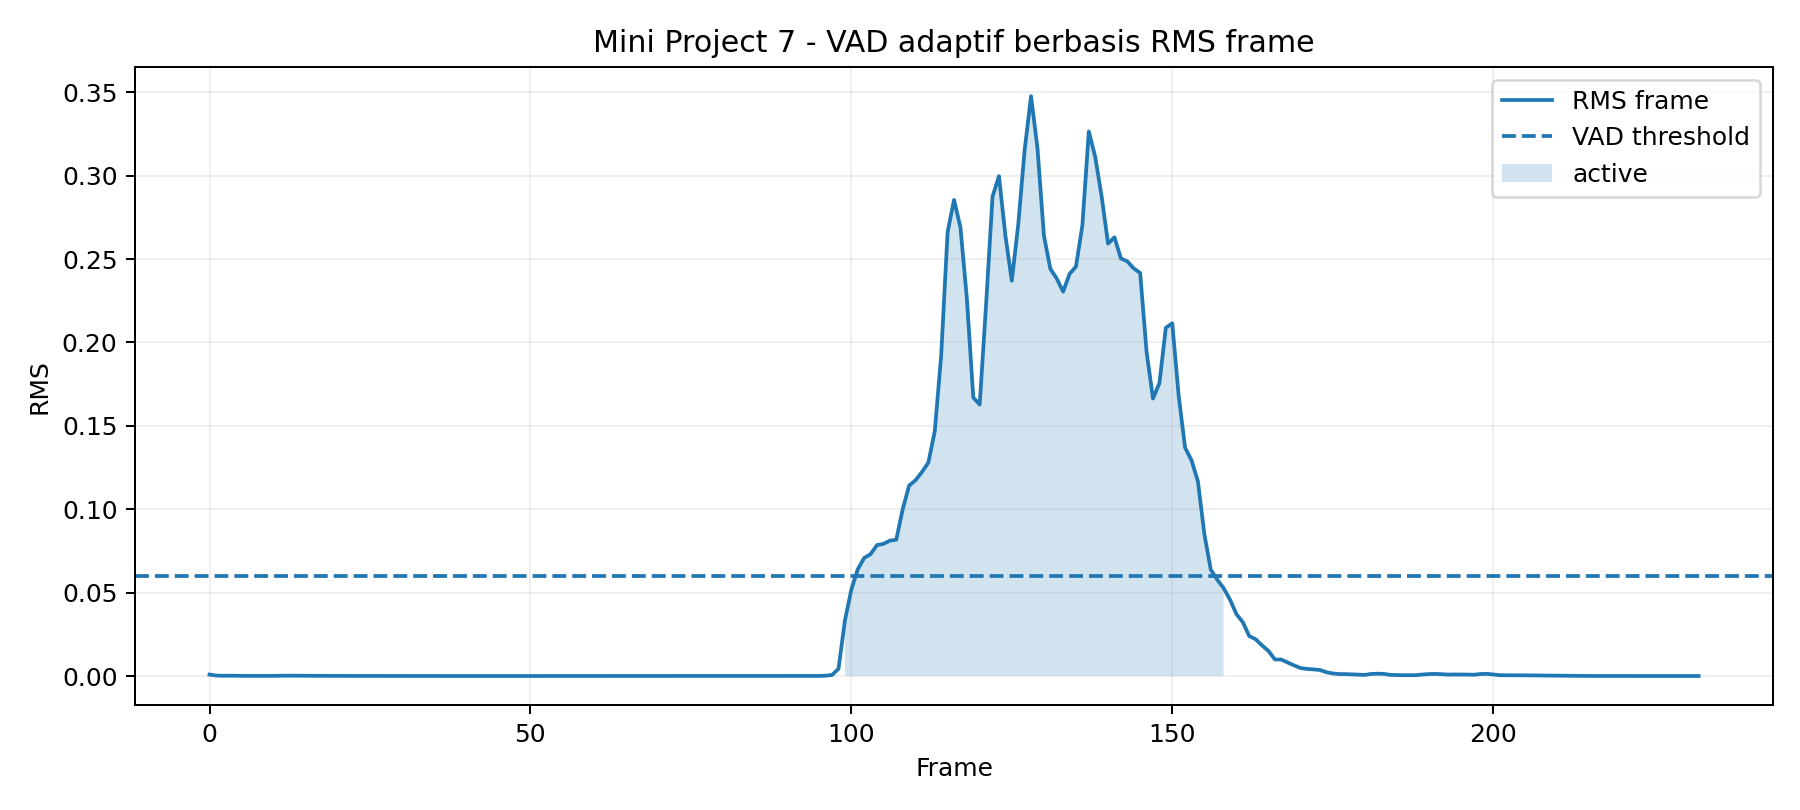

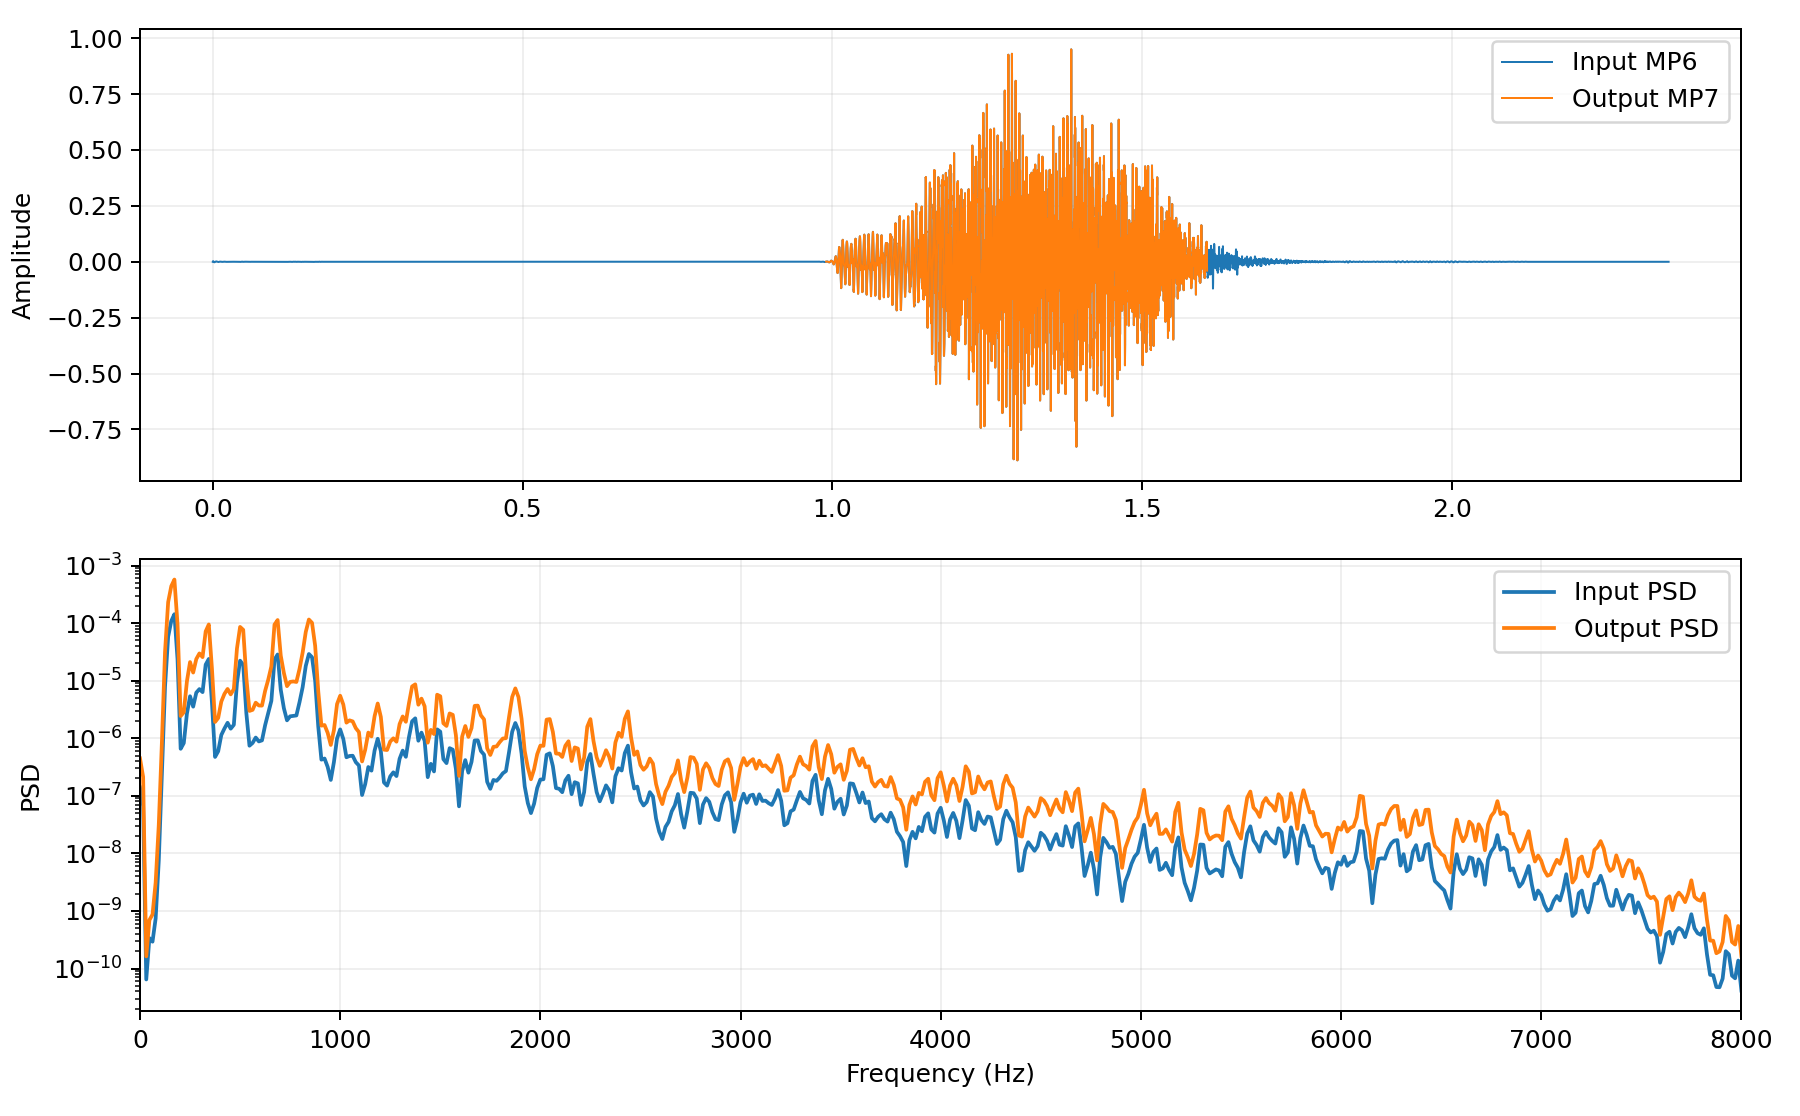

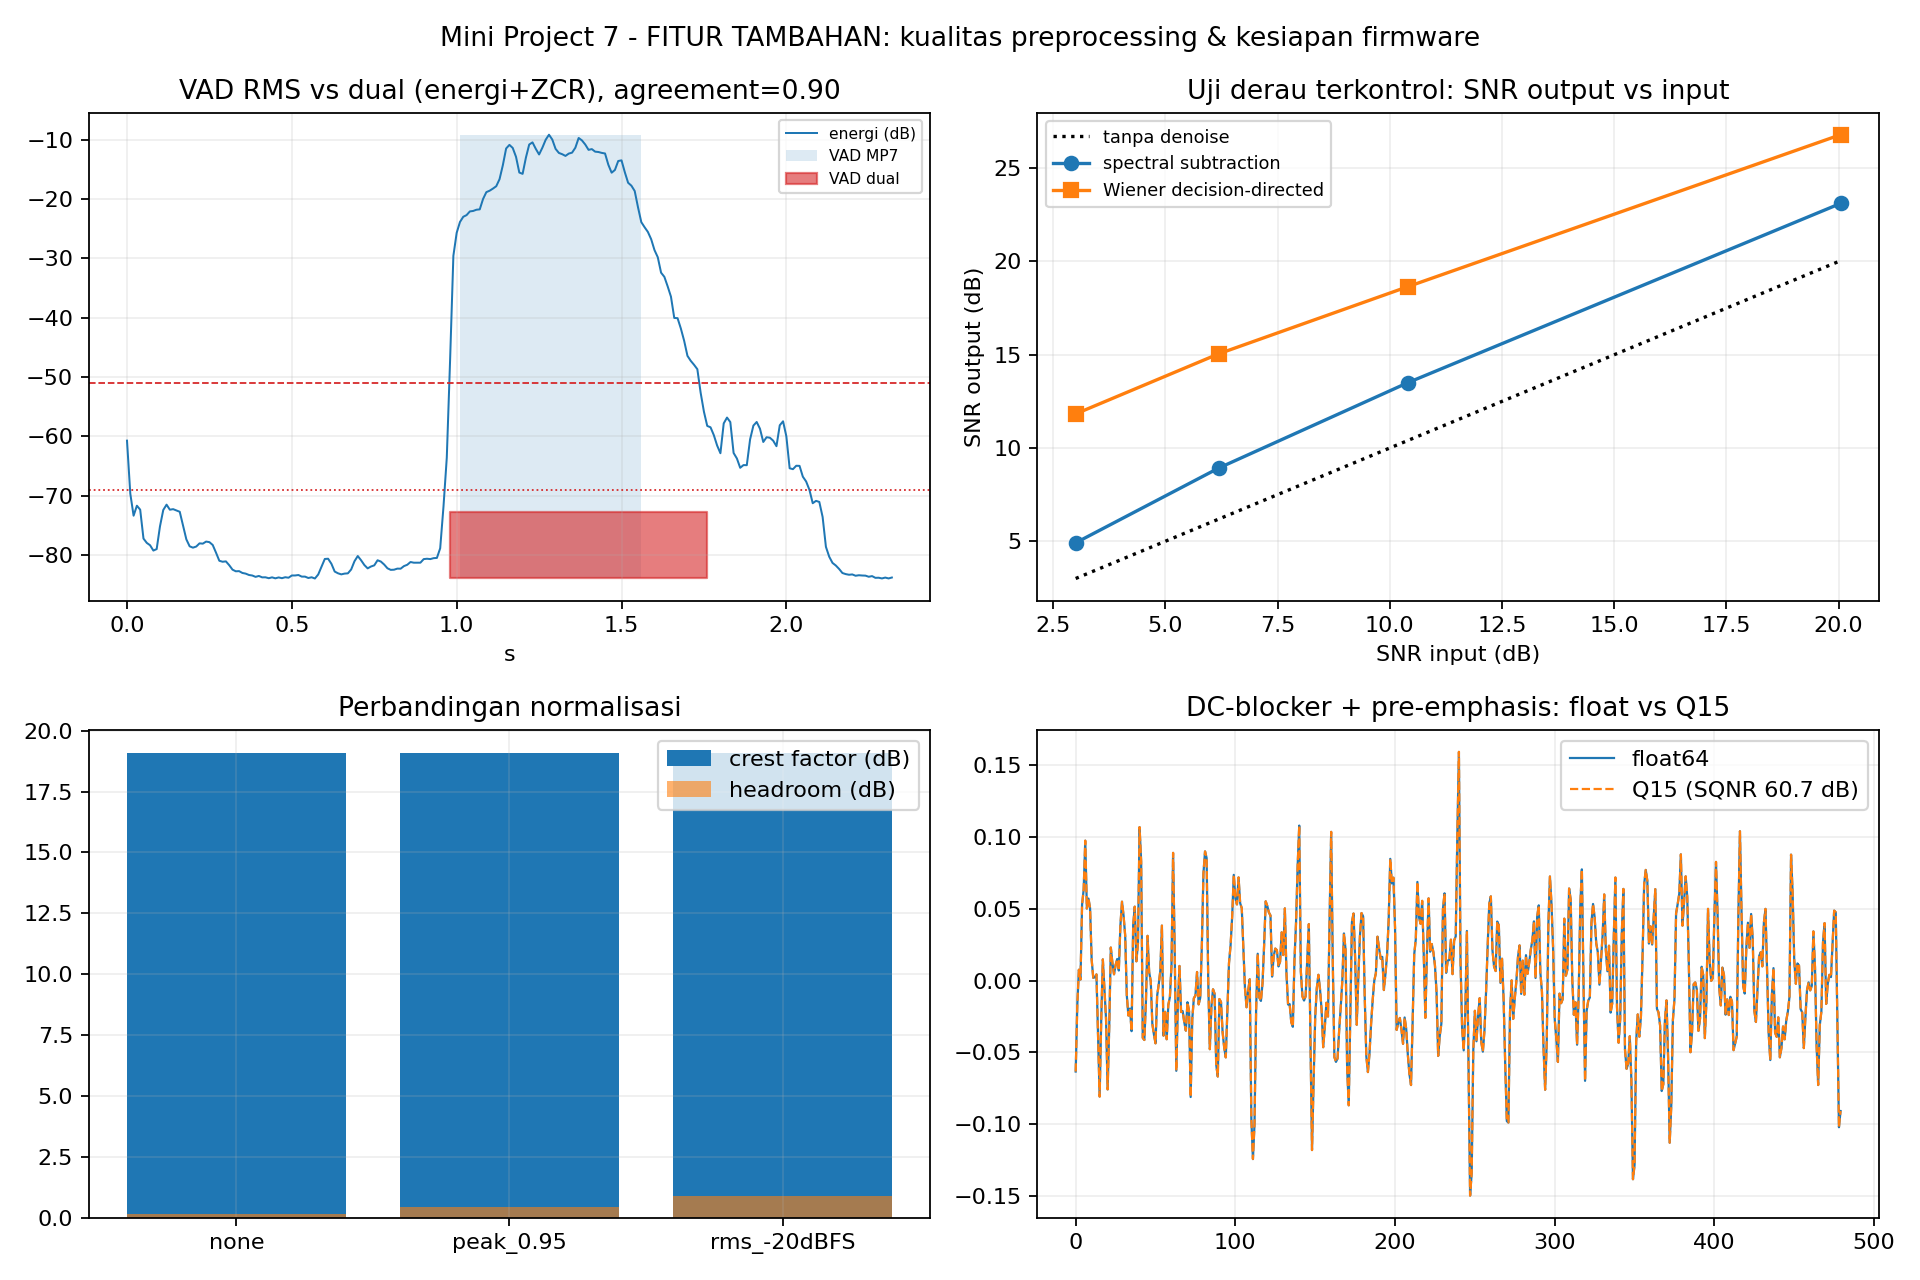

In [18]:
if "__file__" not in globals():  # tampilkan gambar hanya di notebook
    from IPython.display import Image, display
    for p in ['mp07_vad.png', 'mp07_preprocessing_overview.png', 'mp07_extension_preprocessing_analysis.png']:
        display(Image(filename=str(OUT_FIG/p), width=760))